# SPP Initial-Condition Profile Comparison

## Objective

This notebook compares how the choice of initial-condition sampling affects the recovery of the interaction kernel \(\phi\) and the environment force \(f(v)\) in the SPP system.

Two SPP dataset profiles are considered:

1. `baseline`, which uses the original clustered SPP initial conditions.
2. `spp_velocity_grid_clumps`, which uses spatial clumps together with a broader velocity-grid initialization.

The system parameters, learning algorithm, basis construction, solver settings, and evaluation routines are kept fixed as much as possible. The only intended change is the distribution of initial conditions used to generate the training data.

## Scientific Question

The nonparametric estimator only learns the interaction kernel and environment force over regions of state space explored by the data. Therefore, different initial-condition distributions induce different empirical support measures for pairwise distances and velocities. This notebook tests whether broader velocity and spatial support improves recovery of \(f(v)\) and \(\phi(r)\).

## Workflow

For each dataset profile:

1. Generate or load the SPP dataset collection.
2. Extract the training-fit dataset.
3. Build pairwise and environment features.
4. Build the nonparametric B-spline bases.
5. Fit the nonparametric model.
6. Evaluate feature recovery errors for \(\phi\) and \(f\).
7. Visualize:
   - pairwise-distance support density,
   - environment-support density,
   - learned interaction kernel with support,
   - learned environment force with support.
8. Save all figures, summaries, and metadata under:

```text
artifacts/spp/limitation/ic_profile_comparison/

The spp_velocity_grid_clumps profile should provide broader support in the velocity domain than the baseline profile. This is expected to improve recovery of the environment force f(v), especially away from the equilibrium-speed shell sampled by the baseline initialization. Differences in pairwise-distance support may also affect the learned interaction kernel ϕ(r).

## Final directory structure

The notebook saves paper-facing results under:

```text
artifacts/spp/limitation/ic_profile_comparison/
    figures/
        baseline/
            pairwise_distance_support.pdf
            environment_support_density.pdf
            kernel_with_support.pdf
            environment_with_support.pdf
        spp_velocity_grid_clumps/
            pairwise_distance_support.pdf
            environment_support_density.pdf
            kernel_with_support.pdf
            environment_with_support.pdf
        comparison_E_phi_relative.pdf
        comparison_E_f_relative.pdf
    summaries/
        ic_profile_fit_diagnostics.csv
        ic_profile_feature_error_summary.csv
        baseline_density_grids.npz
        spp_velocity_grid_clumps_density_grids.npz
    metadata/
        experiment_metadata.json
        baseline_fit_metadata.json
        spp_velocity_grid_clumps_fit_metadata.json

In [2]:
from pathlib import Path
import sys
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def find_project_root(start: Path) -> Path:
    current = start.resolve()

    while current != current.parent:
        if (current / "src").exists() and (current / "artifacts").exists():
            return current
        if (current / "src").exists():
            return current
        current = current.parent

    raise RuntimeError("Could not locate project root containing src/")


PROJECT_ROOT = find_project_root(Path.cwd())

SRC = PROJECT_ROOT / "src"
ARTIFACTS = PROJECT_ROOT / "artifacts"

if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

print("PROJECT_ROOT:", PROJECT_ROOT)
print("SRC:", SRC)
print("ARTIFACTS:", ARTIFACTS)


#-------------------
# Change working directory to project root
os.chdir(PROJECT_ROOT)
print("CWD:", Path.cwd())

PROJECT_ROOT: .
SRC: ./src
ARTIFACTS: ./artifacts
CWD: .


## 1. Configuration cell

In [3]:
SYSTEM_NAME = "spp"
PROFILE_NAME = "limitation"
TASK_NAME = "ic_profile_comparison"

DATA_PROFILE_NAMES = [
    "baseline",
    "spp_velocity_grid_clumps",
]

TRIAL = 1

TRAIN_SPLIT = "train"
TRAIN_FIT_SPLIT = "train_fit"
TEST_SPLIT = "test"
KDE_SPLIT = "kde"

ALGORITHM = "nonparametric_f"
INTERACTION_TYPE = "energy"

N_PHI = 10
N_F_PER_DIM = 10

RIDGE_LAMBDA = 1e-8
SVD_TOL = 1e-12

FIT_END_TIME = 0.5

In [4]:
TASK_DIR = ARTIFACTS / SYSTEM_NAME / PROFILE_NAME / TASK_NAME

FIGURE_DIR = TASK_DIR / "figures"
TABLE_DIR = TASK_DIR / "tables"
SUMMARY_DIR = TASK_DIR / "summaries"
METADATA_DIR = TASK_DIR / "metadata"

for path in [
    TASK_DIR,
    FIGURE_DIR,
    TABLE_DIR,
    SUMMARY_DIR,
    METADATA_DIR,
]:
    path.mkdir(parents=True, exist_ok=True)

print("TASK_DIR:", TASK_DIR)

TASK_DIR: ./artifacts/spp/limitation/ic_profile_comparison


In [5]:
DATASET_DIR = ARTIFACTS / "datasets" / SYSTEM_NAME
FEATURE_DIR = ARTIFACTS / "features" / SYSTEM_NAME
BASIS_DIR = ARTIFACTS / "bases" / SYSTEM_NAME
FIT_DIR = ARTIFACTS / "fits" / SYSTEM_NAME
ROLLOUT_DIR = ARTIFACTS / "rollouts" / SYSTEM_NAME

print("DATASET_DIR:", DATASET_DIR)
print("FEATURE_DIR:", FEATURE_DIR)
print("BASIS_DIR:", BASIS_DIR)
print("FIT_DIR:", FIT_DIR)
print("ROLLOUT_DIR:", ROLLOUT_DIR)

DATASET_DIR: ./artifacts/datasets/spp
FEATURE_DIR: ./artifacts/features/spp
BASIS_DIR: ./artifacts/bases/spp
FIT_DIR: ./artifacts/fits/spp
ROLLOUT_DIR: ./artifacts/rollouts/spp


In [6]:
from ips_learning.data.dataset_repository import DatasetRepository
from ips_learning.features.feature_builder import FeatureBuilder
from ips_learning.features.feature_repository import FeatureRepository

from ips_learning.bases.specs import (
    BasisConfig,
    RadialBasisSpec,
    EnvironmentBasisSpec,
)
from ips_learning.bases.builders import BasisBuilder
from ips_learning.bases.repository import BasisRepository

from ips_learning.fitting.assembler import NormalEquationAssembler
from ips_learning.fitting.solver import LinearSystemSolver
from ips_learning.fitting.system_repository import NormalSystemRepository

from ips_learning.models.factories import LearnedModelFactory
from ips_learning.rollout.repository import RolloutRepository

from ips_learning.statistics.density_repository import DensityRepository

In [7]:
from ips_learning.experiments.generate_spp_data import build_spp_dataset_profile
from ips_learning.experiments.generate_dataset_collection import (
    generate_standard_dataset_collection,
)

In [8]:
from ips_learning.systems.spp import SPPSystem

In [9]:
dataset_repo = DatasetRepository(root_dir=DATASET_DIR.parent)
feature_repo = FeatureRepository(root_dir=FEATURE_DIR.parent)
basis_repo = BasisRepository(root_dir=BASIS_DIR.parent)
fit_repo = NormalSystemRepository(root_dir=FIT_DIR.parent)
rollout_repo = RolloutRepository(root_dir=ROLLOUT_DIR.parent)
density_repo = DensityRepository(root=ARTIFACTS / "densities")

In [10]:
def prefixed_name(data_profile_name: str, base_name: str) -> str:
    return f"{data_profile_name}_{base_name}"


def train_dataset_name(data_profile_name: str) -> str:
    return prefixed_name(
        data_profile_name,
        f"dataset_train_trial_{TRIAL:03d}",
    )


def train_fit_dataset_name(data_profile_name: str) -> str:
    return prefixed_name(
        data_profile_name,
        f"dataset_train_fit_trial_{TRIAL:03d}",
    )


def test_dataset_name(data_profile_name: str) -> str:
    return prefixed_name(data_profile_name, "dataset_test")


def kde_dataset_name(data_profile_name: str) -> str:
    return prefixed_name(data_profile_name, "dataset_kde")


def feature_name(data_profile_name: str) -> str:
    return train_fit_dataset_name(data_profile_name)


def basis_name(data_profile_name: str) -> str:
    return f"{train_fit_dataset_name(data_profile_name)}_nphi_{N_PHI}_nf_{N_F_PER_DIM}"


def fit_case_name(data_profile_name: str) -> str:
    return f"ic_profile_{data_profile_name}"

In [11]:
def save_json(obj, path: Path) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w") as f:
        json.dump(obj, f, indent=2)


experiment_metadata = {
    "system_name": SYSTEM_NAME,
    "profile_name": PROFILE_NAME,
    "task_name": TASK_NAME,
    "data_profile_names": DATA_PROFILE_NAMES,
    "algorithm": ALGORITHM,
    "interaction_type": INTERACTION_TYPE,
    "n_phi": N_PHI,
    "n_f_per_dim": N_F_PER_DIM,
    "ridge_lambda": RIDGE_LAMBDA,
    "svd_tol": SVD_TOL,
    "fit_end_time": FIT_END_TIME,
}

save_json(
    experiment_metadata,
    METADATA_DIR / "experiment_metadata.json",
)

## Generate datasets

Each initial-condition profile is generated with profile-specific dataset names to avoid overwriting artifacts.

In [12]:
def generate_profile_datasets(data_profile_name: str):
    profile = build_spp_dataset_profile(data_profile_name,  dataset_prefix=data_profile_name,)


    outputs = generate_standard_dataset_collection(
        profile=profile,
        save_train_fit_split=True,
        fit_end_time=FIT_END_TIME,
        fit_split_name=TRAIN_FIT_SPLIT,
        fit_name_template=(
            f"{data_profile_name}_dataset_train_fit_trial_{{trial:03d}}"
        ),
    )

    return outputs

In [13]:
for data_profile_name in DATA_PROFILE_NAMES:
    print(f"Generating/loading datasets for profile: {data_profile_name}")
    generate_profile_datasets(data_profile_name)

Generating/loading datasets for profile: baseline
Simulating trajectory 2/20
Simulating trajectory 4/20
Simulating trajectory 6/20
Simulating trajectory 8/20
Simulating trajectory 10/20
Simulating trajectory 12/20
Simulating trajectory 14/20
Simulating trajectory 16/20
Simulating trajectory 18/20
Simulating trajectory 20/20
Simulating trajectory 2/20
Simulating trajectory 4/20
Simulating trajectory 6/20
Simulating trajectory 8/20
Simulating trajectory 10/20
Simulating trajectory 12/20
Simulating trajectory 14/20
Simulating trajectory 16/20
Simulating trajectory 18/20
Simulating trajectory 20/20
Simulating trajectory 2/20
Simulating trajectory 4/20
Simulating trajectory 6/20
Simulating trajectory 8/20
Simulating trajectory 10/20
Simulating trajectory 12/20
Simulating trajectory 14/20
Simulating trajectory 16/20
Simulating trajectory 18/20
Simulating trajectory 20/20
Simulating trajectory 2/20
Simulating trajectory 4/20
Simulating trajectory 6/20
Simulating trajectory 8/20
Simulating tra

## Load datasets

In [14]:
def load_profile_datasets(data_profile_name: str):
    train = dataset_repo.load(
        system_name=SYSTEM_NAME,
        split=TRAIN_SPLIT,
        dataset_name=train_dataset_name(data_profile_name),
    )

    train_fit = dataset_repo.load(
        system_name=SYSTEM_NAME,
        split=TRAIN_FIT_SPLIT,
        dataset_name=train_fit_dataset_name(data_profile_name),
    )

    test = dataset_repo.load(
        system_name=SYSTEM_NAME,
        split=TEST_SPLIT,
        dataset_name=test_dataset_name(data_profile_name),
    )

    kde = dataset_repo.load(
        system_name=SYSTEM_NAME,
        split=KDE_SPLIT,
        dataset_name=kde_dataset_name(data_profile_name),
    )

    return {
        "train": train,
        "train_fit": train_fit,
        "test": test,
        "kde": kde,
    }

In [15]:
datasets_by_profile = {
    data_profile_name: load_profile_datasets(data_profile_name)
    for data_profile_name in DATA_PROFILE_NAMES
}

for name, data in datasets_by_profile.items():
    ds = data["train_fit"]
    print(name)
    print("X:", ds.X.shape)
    print("V:", ds.V.shape)
    print("LHS:", ds.LHS.shape)
    print("t:", ds.t.shape)

baseline
X: (20, 51, 10, 2)
V: (20, 51, 10, 2)
LHS: (20, 51, 10, 2)
t: (51,)
spp_velocity_grid_clumps
X: (50, 51, 10, 2)
V: (50, 51, 10, 2)
LHS: (50, 51, 10, 2)
t: (51,)


## Build features

In [16]:
def build_and_save_features(data_profile_name: str, train_fit_dataset):
    f_name = feature_name(data_profile_name)

    features = FeatureBuilder().build(train_fit_dataset)

    feature_repo.save(
        features=features,
        system_name=SYSTEM_NAME,
        split=TRAIN_FIT_SPLIT,
        feature_name=f_name,
        overwrite=True,
    )

    return features

In [17]:
features_by_profile = {}

for data_profile_name in DATA_PROFILE_NAMES:
    print(f"Building features for {data_profile_name}")
    features_by_profile[data_profile_name] = build_and_save_features(
        data_profile_name,
        datasets_by_profile[data_profile_name]["train_fit"],
    )

Building features for baseline
Building features for spp_velocity_grid_clumps


## Build bases

In [18]:
basis_config = BasisConfig(
    radial=RadialBasisSpec(
        family="bspline",
        degree=1,
        n_basis=N_PHI,
    ),
    environment=EnvironmentBasisSpec(
        family="bspline",
        degree=1,
        n_basis_per_dim=N_F_PER_DIM,
    ),
)

In [19]:
def build_and_save_basis(data_profile_name: str, features):
    b_name = basis_name(data_profile_name)

    basis_bundle = BasisBuilder(basis_config).build(
        features=features,
    )

    basis_repo.save(
        basis_bundle=basis_bundle,
        system_name=SYSTEM_NAME,
        split=TRAIN_FIT_SPLIT,
        basis_name=b_name,
        overwrite=True,
    )

    return basis_bundle

In [20]:
basis_by_profile = {}

for data_profile_name in DATA_PROFILE_NAMES:
    print(f"Building basis for {data_profile_name}")
    basis_by_profile[data_profile_name] = build_and_save_basis(
        data_profile_name,
        features_by_profile[data_profile_name],
    )

Building basis for baseline
Building basis for spp_velocity_grid_clumps


## Fit nonparametric models

In [21]:
solver = LinearSystemSolver(
    method="lstsq",
    ridge_lambda=RIDGE_LAMBDA,
    svd_tol=SVD_TOL,
)

assembler = NormalEquationAssembler(
    parallel_jobs=1,
    interaction_type=INTERACTION_TYPE,
    algorithm=ALGORITHM,
)

In [22]:
def fit_profile_model(data_profile_name: str):
    features = features_by_profile[data_profile_name]
    basis_bundle = basis_by_profile[data_profile_name]
    f_case = fit_case_name(data_profile_name)

    fit_result = assembler.fit(
        features=features,
        basis_bundle=basis_bundle,
        solver=solver,
        system_name=SYSTEM_NAME,
    )

    fit_result.metadata.update({
        "system_name": SYSTEM_NAME,
        "profile_name": PROFILE_NAME,
        "task_name": TASK_NAME,
        "data_profile_name": data_profile_name,
        "fit_case_name": f_case,
        "algorithm": ALGORITHM,
        "interaction_type": INTERACTION_TYPE,
        "feature_name": feature_name(data_profile_name),
        "basis_name": basis_name(data_profile_name),
        "n_phi": N_PHI,
        "n_f_per_dim": N_F_PER_DIM,
        "ridge_lambda": RIDGE_LAMBDA,
        "svd_tol": SVD_TOL,
    })

    fit_repo.save_fit_result(
        system_name=SYSTEM_NAME,
        profile_name=PROFILE_NAME,
        algorithm=ALGORITHM,
        fit_case_name=f_case,
        fit_result=fit_result,
        overwrite=True,
    )

    save_json(
        fit_result.metadata,
        METADATA_DIR / f"{data_profile_name}_fit_metadata.json",
    )

    return fit_result

In [23]:
fit_results_by_profile = {}

for data_profile_name in DATA_PROFILE_NAMES:
    print(f"Fitting model for {data_profile_name}")
    fit_results_by_profile[data_profile_name] = fit_profile_model(
        data_profile_name
    )

Fitting model for baseline
Fitting model for spp_velocity_grid_clumps


## Build learned models

In [24]:
learned_models_by_profile = {}

for data_profile_name in DATA_PROFILE_NAMES:
    ds = datasets_by_profile[data_profile_name]["train_fit"]
    fit_result = fit_results_by_profile[data_profile_name]

    learned_models_by_profile[data_profile_name] = (
        LearnedModelFactory().build_from_fit_result(
            fit_result=fit_result,
            N=int(ds.metadata["N"]),
            D=int(ds.metadata["D"]),
        )
    )

## Save fit diagnostic summary

In [25]:
diagnostic_rows = []

for data_profile_name, fit_result in fit_results_by_profile.items():
    diag = fit_result.diagnostics

    diagnostic_rows.append({
        "data_profile_name": data_profile_name,
        "condition_number": diag.condition_number,
        "rank": diag.rank,
        "min_singular": diag.min_singular,
        "max_singular": diag.max_singular,
        "n_phi": N_PHI,
        "n_f_per_dim": N_F_PER_DIM,
    })

fit_diagnostics_df = pd.DataFrame(diagnostic_rows)
fit_diagnostics_df.to_csv(
    SUMMARY_DIR / "ic_profile_fit_diagnostics.csv",
    index=False,
)

fit_diagnostics_df

,data_profile_name,condition_number,rank,min_singular,max_singular,n_phi,n_f_per_dim
0,baseline,1.367966e+16,210,1.038812e-17,0.142106,10,10
1,spp_velocity_grid_clumps,2.609660e+04,210,3.643276e-05,0.950771,10,10


## Visualization helper paths

In [26]:
def profile_figure_dir(data_profile_name: str) -> Path:
    path = FIGURE_DIR / data_profile_name
    path.mkdir(parents=True, exist_ok=True)
    return path

In [27]:
_, _, N, D = datasets_by_profile["baseline"]["train_fit"].X.shape
true_phi = SPPSystem(N=N, D=D).kernel
true_f = SPPSystem(N=N, D=D).f_env

## Plot learned kernel with support

In [28]:
from ips_learning.visualization.learned_functions import LearnedFunctionVisualizer
viz = LearnedFunctionVisualizer()

from ips_learning.visualization.utils import FigureRepository


from ips_learning.statistics.density import (
    KernelDensityEstimator,
    EnvironmentDensityEstimator,
)

In [29]:
for data_profile_name in DATA_PROFILE_NAMES:
    fig_dir = profile_figure_dir(data_profile_name)

    learned_model = learned_models_by_profile[data_profile_name]
    basis_bundle = basis_by_profile[data_profile_name]
    features = features_by_profile[data_profile_name]

    loc = basis_bundle.localization_metadata

    r_min = float(loc["r_min"])
    r_max = float(loc["r_max"])

    r_grid = np.linspace(r_min, r_max, 500)

    train_density_est = KernelDensityEstimator().fit_from_R(
        features.R,
        bandwidth=None,
        kernel="gaussian",
    )

    train_density = train_density_est.evaluate(r_grid)

    fig_kernel = viz.plot_kernel_with_support(
        learned_model=learned_model,
        basis_bundle=basis_bundle,
        r_grid=r_grid,
        train_density=train_density,
        true_kernel=true_phi,
        labels={
            "true_kernel_label": r"$\phi(r)$",
            "learned_kernel_label": r"$\tilde{\phi}(r)$",
            "train_density_label": r"$\widehat{\rho}_R(r)$",
            "xlabel": r"$r$ (pairwise distance)",
            "y1label": "kernel",
            "y2label": "density",
            "legend_loc": "best",
            "legend_bbox_to_anchor": None,
        },
    )
    figure_repo = FigureRepository(root_dir=profile_figure_dir(data_profile_name))

    figure_repo.save(
        fig_kernel,
        system_name=SYSTEM_NAME,
        stage_name=TASK_NAME,
        file_name=f"kernel_with_support_{data_profile_name}",
    )





In [53]:
# Combined kernel comparison with profile-specific empirical densities
profile_labels = {
    DATA_PROFILE_NAMES[0]: "Profile 1",
    DATA_PROFILE_NAMES[1]: "Profile 2",
}

# Use one common radial interval so the learned kernels are directly comparable.
r_min_common = min(
    float(basis_by_profile[name].localization_metadata["r_min"])
    for name in DATA_PROFILE_NAMES
)
r_max_common = max(
    float(basis_by_profile[name].localization_metadata["r_max"])
    for name in DATA_PROFILE_NAMES
)
r_grid_common = np.linspace(r_min_common, r_max_common, 500)
r_eval_common = r_grid_common.reshape(-1, 1)

# Estimate each profile's distance density separately.
kernel_density_by_profile = {}
for data_profile_name in DATA_PROFILE_NAMES:
    density_estimator = KernelDensityEstimator().fit_from_R(
        features_by_profile[data_profile_name].R,
        bandwidth=None,
        kernel="gaussian",
    )
    kernel_density_by_profile[data_profile_name] = density_estimator.evaluate(
        r_grid_common
    )

fig_kernel, ax_kernel = plt.subplots(figsize=(9.2, 5.4))
ax_density = ax_kernel.twinx()

ax_kernel.plot(
    r_grid_common,
    np.asarray(true_phi(r_eval_common), dtype=float).reshape(-1),
    color="black",
    linewidth=2.5,
    label=r"$\phi(r)$",
)

line_styles = ["--", "-."]
for line_style, data_profile_name in zip(line_styles, DATA_PROFILE_NAMES):
    learned_model = learned_models_by_profile[data_profile_name]
    phi_hat = np.asarray(
        learned_model.learned_kernel(r_eval_common),
        dtype=float,
    ).reshape(-1)

    # Hide extrapolated values outside this profile's basis support.
    loc = basis_by_profile[data_profile_name].localization_metadata
    support_mask = (
        (r_grid_common >= float(loc["r_min"]))
        & (r_grid_common <= float(loc["r_max"]))
    )
    phi_hat = np.where(support_mask, phi_hat, np.nan)

    kernel_line = ax_kernel.plot(
        r_grid_common,
        phi_hat,
        linestyle=line_style,
        linewidth=2.2,
        label=rf"$\hat{{\phi}}(r)$:{profile_labels[data_profile_name]}",
    )[0]

    # Plot this profile's own empirical pairwise-distance density.
    ax_density.plot(
        r_grid_common,
        kernel_density_by_profile[data_profile_name],
        linestyle=line_style,
        linewidth=1.8,
        alpha=0.75,
        color=kernel_line.get_color(),
        label=rf"$\widehat{{\rho}}_R(r)$:{profile_labels[data_profile_name]}",
    )

ax_kernel.set_xlabel(r"$r$")
ax_kernel.set_ylabel("kernel")
ax_density.set_ylabel("density")
ax_kernel.set_xlim(r_min_common, r_max_common)

handles_1, labels_1 = ax_kernel.get_legend_handles_labels()
handles_2, labels_2 = ax_density.get_legend_handles_labels()
ax_kernel.legend(handles_1 + handles_2, labels_1 + labels_2, loc=1)

fig_kernel.tight_layout()

figure_repo = FigureRepository(root_dir=FIGURE_DIR)
figure_repo.save(
    fig_kernel,
    system_name=SYSTEM_NAME,
    stage_name=TASK_NAME,
    file_name="kernel_profile_comparison_separate_densities",
)


PosixPath('./artifacts/spp/limitation/ic_profile_comparison/figures/spp/figures/ic_profile_comparison/kernel_profile_comparison_separate_densities.png')

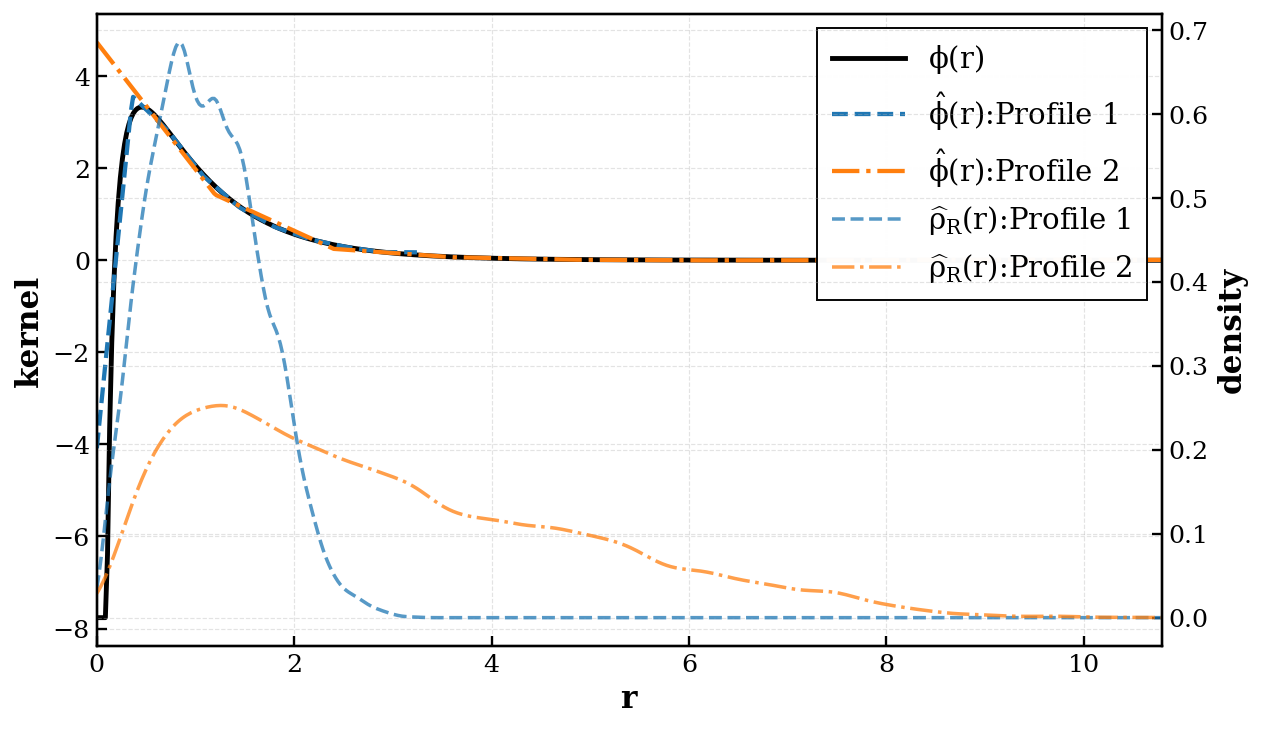

In [54]:
fig_kernel

## Plot learned environment force with support

In [32]:
for data_profile_name in DATA_PROFILE_NAMES:
    fig_dir = profile_figure_dir(data_profile_name)

    learned_model = learned_models_by_profile[data_profile_name]
    basis_bundle = basis_by_profile[data_profile_name]
    features = features_by_profile[data_profile_name]

    loc = basis_bundle.localization_metadata

    env_min = np.asarray(loc.get("env_min", loc.get("v_min")), dtype=float)
    env_max = np.asarray(loc.get("env_max", loc.get("v_max")), dtype=float)

    z1_grid = np.linspace(env_min[0], env_max[0], 120)
    z2_grid = np.linspace(env_min[1], env_max[1], 120)

    Z_samples = np.asarray(features.V, dtype=float)
    train_env_density_ref = EnvironmentDensityEstimator().fit_from_Z(
            Z_samples,
            bandwidth=None,
            kernel="gaussian",
        )
    train_density_grid = train_env_density_ref.evaluate_on_grid(z1_grid, z2_grid)

    fig_f = viz.plot_environment_with_support(
    learned_model=learned_model,
    z1_grid=z1_grid,
    z2_grid=z2_grid,
    reference_density=train_density_grid,
    true_env=true_f,
    environment_variable="v",
    labels={
        "x1_label": r"$v_1$",
        "x2_label": r"$v_2$",
        "true_comp1_label": r"$f_{1}$",
        "true_comp2_label": r"$f_{2}$",
        "learned_comp1_label": r"$\hat f_{1}$",
        "learned_comp2_label": r"$\hat f_{2}$",
        "colorbar_label": "density",
    },
    )
    figure_repo = FigureRepository(root_dir=profile_figure_dir(data_profile_name))
    figure_repo.save(
        fig_f,
        system_name=SYSTEM_NAME,
        stage_name=TASK_NAME,
        file_name=f"learned_f_{data_profile_name}",
    )
  


In [51]:
# Combined 2 x 3 environment-force comparison with profile-specific densities
# Rows: force components f_1 and f_2
# Columns: true force, learned force from profile 1, learned force from profile 2
profile_labels = {
    DATA_PROFILE_NAMES[0]: r"$\hat{f}$ :Profile 1",
    DATA_PROFILE_NAMES[1]: r"$\hat{f}$ :Profile 2",
}

# Use the union of the two learned environment domains for a common comparison grid.
env_mins = []
env_maxs = []
for data_profile_name in DATA_PROFILE_NAMES:
    loc = basis_by_profile[data_profile_name].localization_metadata
    env_mins.append(np.asarray(loc.get("env_min", loc.get("v_min")), dtype=float))
    env_maxs.append(np.asarray(loc.get("env_max", loc.get("v_max")), dtype=float))

env_min_common = np.min(np.vstack(env_mins), axis=0)
env_max_common = np.max(np.vstack(env_maxs), axis=0)

z1_grid = np.linspace(env_min_common[0], env_max_common[0], 120)
z2_grid = np.linspace(env_min_common[1], env_max_common[1], 120)
Z1, Z2 = np.meshgrid(z1_grid, z2_grid, indexing="ij")
Z_grid = np.column_stack((Z1.ravel(), Z2.ravel()))


def evaluate_environment(env_fn):
    return np.asarray(env_fn(Z_grid), dtype=float).reshape(*Z1.shape, 2)


f_true_grid = evaluate_environment(true_f)
f_hat_by_profile = {
    name: evaluate_environment(
        learned_models_by_profile[name].learned_environment
    )
    for name in DATA_PROFILE_NAMES
}

# Estimate each profile's velocity density independently.
env_density_by_profile = {}
for data_profile_name in DATA_PROFILE_NAMES:
    Z_samples = np.asarray(
        features_by_profile[data_profile_name].V,
        dtype=float,
    )

    density_estimator = EnvironmentDensityEstimator().fit_from_Z(
        Z_samples,
        bandwidth=None,
        kernel="gaussian",
    )
    env_density_by_profile[data_profile_name] = density_estimator.evaluate_on_grid(
        z1_grid,
        z2_grid,
    )

# ------------------------------------------------------------
# Profile-specific densities with one shared color scale
# ------------------------------------------------------------

# The density values remain different for each profile.
# Only the normalization and colormap are shared so that one
# colorbar represents the actual density values in both columns.
all_density_values = np.concatenate([
    env_density_by_profile[data_profile_name].ravel()
    for data_profile_name in DATA_PROFILE_NAMES
])

shared_density_min = float(np.min(all_density_values))
shared_density_max = float(np.max(all_density_values))

if np.isclose(shared_density_min, shared_density_max):
    shared_density_max = shared_density_min + 1e-12

shared_density_norm = plt.Normalize(
    vmin=shared_density_min,
    vmax=shared_density_max,
)

shared_density_cmap = plt.cm.plasma

profile_facecolors = {
    data_profile_name: shared_density_cmap(
        shared_density_norm(
            env_density_by_profile[data_profile_name]
        )
    )
    for data_profile_name in DATA_PROFILE_NAMES
}

# Shared z-limits within each row make component-wise comparison meaningful.
row_zlims = {}
for comp in range(2):
    values = [f_true_grid[:, :, comp].ravel()]
    values.extend(
        f_hat_by_profile[name][:, :, comp].ravel()
        for name in DATA_PROFILE_NAMES
    )
    values = np.concatenate(values)
    z_min = float(np.min(values))
    z_max = float(np.max(values))
    pad = 1e-6 if np.isclose(z_min, z_max) else 0.05 * (z_max - z_min)
    row_zlims[comp] = (z_min - pad, z_max + pad)

fig_f, axes = plt.subplots(
    2,
    3,
    figsize=(17.5, 9.5),
    subplot_kw={"projection": "3d"},
)

column_titles = [
    r"$f$",
    profile_labels[DATA_PROFILE_NAMES[0]],
    profile_labels[DATA_PROFILE_NAMES[1]],
]
column_surfaces = [
    f_true_grid,
    f_hat_by_profile[DATA_PROFILE_NAMES[0]],
    f_hat_by_profile[DATA_PROFILE_NAMES[1]],
]

# The true-force column is neutral because there is no single density shared by both profiles.
true_facecolors = np.full((*Z1.shape, 4), (0.72, 0.72, 0.72, 1.0))
column_facecolors = [
    true_facecolors,
    profile_facecolors[DATA_PROFILE_NAMES[0]],
    profile_facecolors[DATA_PROFILE_NAMES[1]],
]

for comp in range(2):
    for col, (title, surface_values, facecolors) in enumerate(
        zip(column_titles, column_surfaces, column_facecolors)
    ):
        ax = axes[comp, col]
        ax.plot_surface(
            Z1,
            Z2,
            surface_values[:, :, comp],
            facecolors=facecolors,
            linewidth=0,
            antialiased=False,
            shade=False,
        )
        ax.set_xlim(float(z1_grid.min()), float(z1_grid.max()))
        ax.set_ylim(float(z2_grid.min()), float(z2_grid.max()))
        ax.set_zlim(*row_zlims[comp])
        ax.set_xlabel(r"$v_1$", labelpad=6)
        ax.set_ylabel(r"$v_2$", labelpad=6)
        ax.view_init(elev=25, azim=45)
        ax.tick_params(pad=2)

        if comp == 0:
            ax.set_title(title)
        if col == 0:
            ax.set_zlabel(rf"$f_{comp + 1}$", labelpad=8)

# ------------------------------------------------------------
# One colorbar for both profile-specific density surfaces
# ------------------------------------------------------------
density_mappable = plt.cm.ScalarMappable(
    norm=shared_density_norm,
    cmap=shared_density_cmap,
)
density_mappable.set_array([])

cbar = fig_f.colorbar(
    density_mappable,
    ax=axes[:, 1:].ravel().tolist(),
    shrink=0.72,
    pad=0.04,
)

cbar.set_label(
    r"density"
)

# fig_f.subplots_adjust(
#     left=0.04,
#     right=0.90,
#     bottom=0.06,
#     top=0.92,
#     wspace=0.05,
#     hspace=0.08,
# )

figure_repo = FigureRepository(root_dir=FIGURE_DIR)
figure_repo.save(
    fig_f,
    system_name=SYSTEM_NAME,
    stage_name=TASK_NAME,
    file_name="environment_force_profile_comparison_2x3_separate_densities",
)


PosixPath('./artifacts/spp/limitation/ic_profile_comparison/figures/spp/figures/ic_profile_comparison/environment_force_profile_comparison_2x3_separate_densities.png')

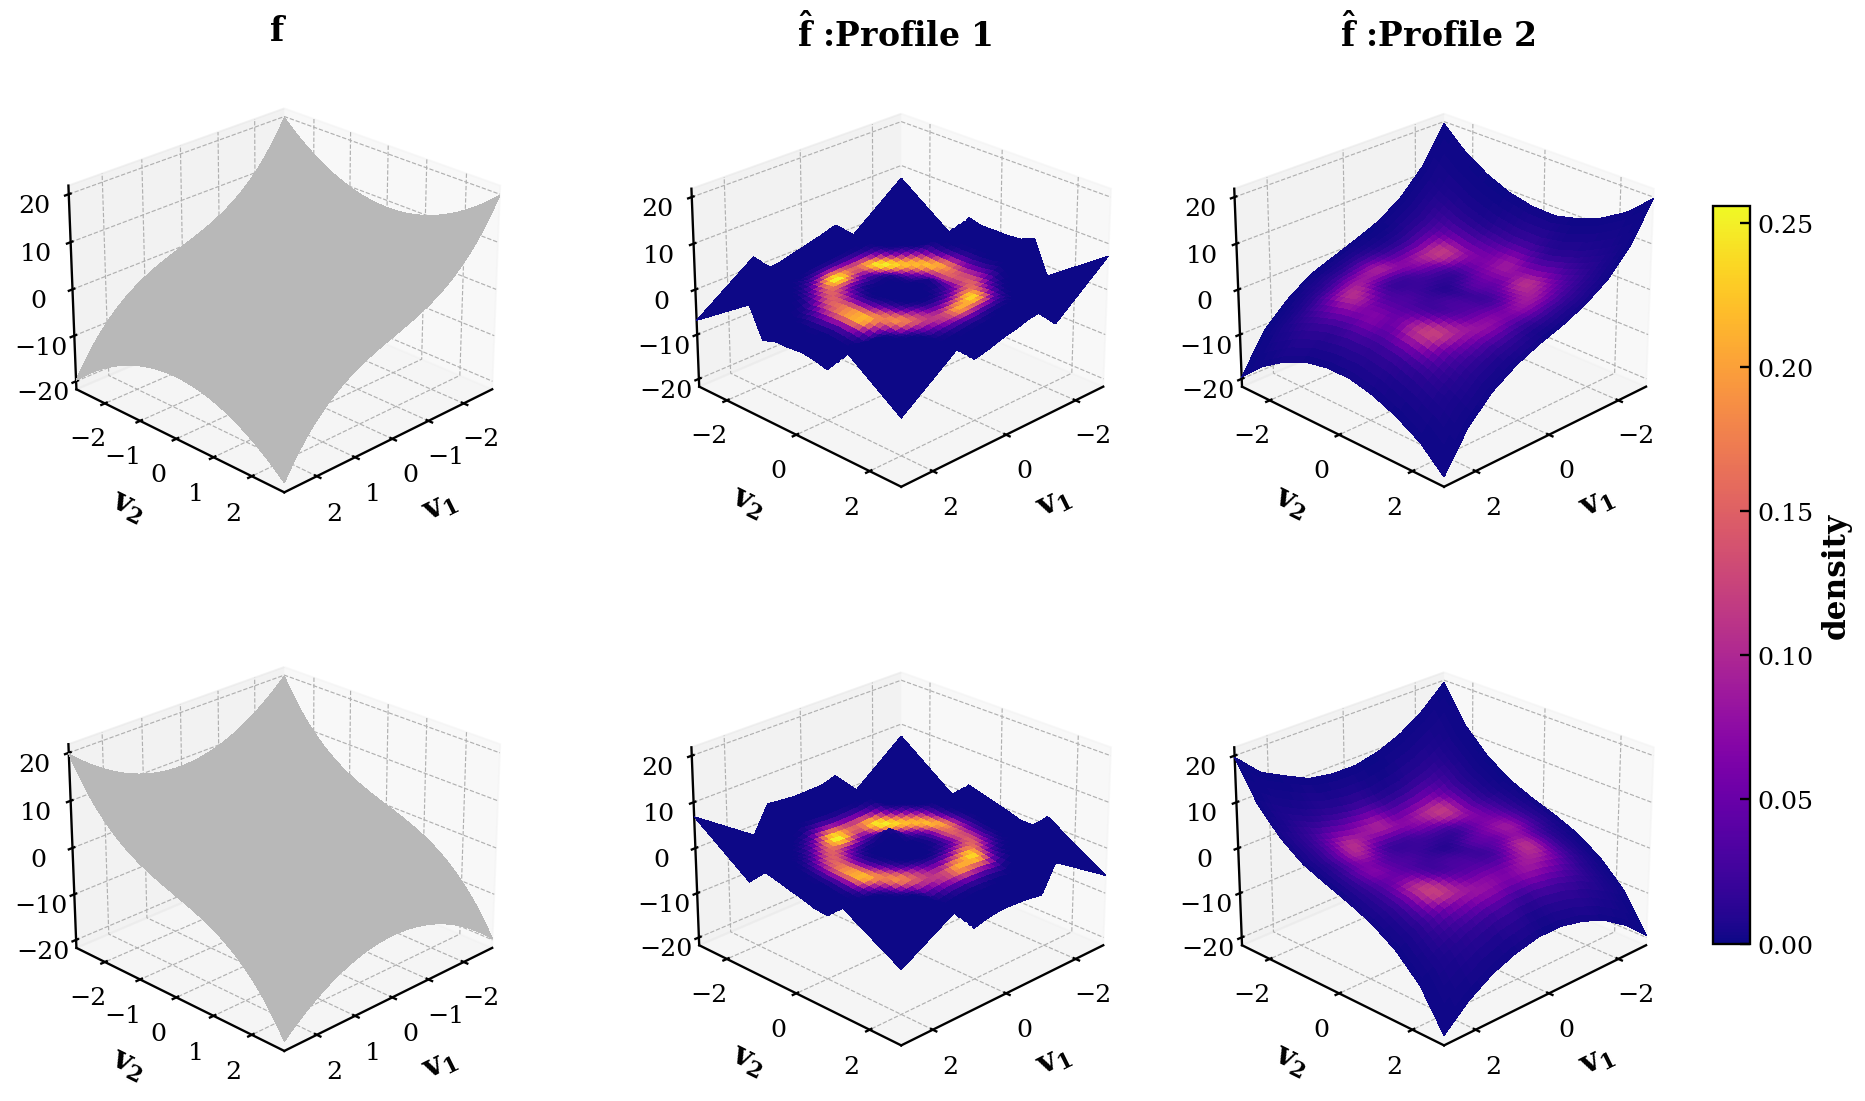

In [52]:
fig_f